# INSY 674 · Fine-Tuning the System: Tuning, Ensembles and Final Test

## Summary

**Final model: a stacking ensemble of the five shortlisted models** (random forest, XGBoost, KNN, LightGBM and neural network). A logistic regression combines their purchase probabilities. Every member is tuned, except the neural network, whose comparison setting was already the best.

- **Cross-validation estimate:** AP 0.757 ± 0.013 on 15 fresh folds.
- **Test set:** **AP 0.762** (95 % CI 0.721–0.804) and ROC-AUC 0.938, against 0.156 for random ranking and 0.622 for the rule "rank sessions by `PageValues`".
- **At the threshold fixed on training data (0.373):** the model finds **71 % of buyers (271 of 382) with 69 % precision**, F1 0.699. It makes 123 false alarms, against 233 for the `PageValues` rule.

**Main findings**

1. **Tuning gains,** all measured on 15 fresh folds that played no part in the tuning:

   | Model | AP before → after | Folds improved | What changed |
   |---|---|---|---|
   | **XGBoost** | 0.721 → 0.754 (**+0.033**) | **15/15** | Its defaults (learning rate 0.3, depth 6) overfit after only about 10 trees. Learning rate 0.02 with 175 trees, `min_child_weight` 9, `gamma` 2.2, row sampling 0.8 and class weight 2.32 fix this. |
   | **KNN** | 0.721 → 0.736 (**+0.015**) | **15/15** | k 25 → 65 with uniform votes, Manhattan distance, **RobustScaler**, and the category block down-weighted to 0.5. |
   | **Random forest** | 0.747 → 0.754 (**+0.007**) | 14/15 | Leaves of at least 20 sessions instead of 1, `max_features` 0.3, bootstrap samples of 60 %, entropy. Train AP falls from 1.0 to 0.81. |
   | **LightGBM** | 0.745 → 0.752 (+0.006) | 11/15 | At least 100 sessions per leaf, `min_split_gain` 0.48, L1 penalty 2.6, learning rate 0.01 with 350 trees. |
   | **Neural network** | 0.730 → 0.730 (0) | — | The comparison setting ranked first of 51 candidates, so it was kept. |

2. **Transformation choices were tuned together with the model hyperparameters, and several flipped.**
   - The **engineered features were dropped** by every model, including XGBoost and LightGBM, which had used them in the comparison.
   - **Rare-category grouping** was chosen by all tree models.
   - The random forest went back to **all 17 inputs** once its trees were regularized.
3. **Ensembles help a little.** Stacking all five models beats the best single model (tuned XGBoost, 0.754) by +0.003 and the 3-tree stack by +0.001. The stacker weights XGBoost most (4.2), then the random forest (1.4) and the neural network (1.2). KNN gets 0.3, and LightGBM gets a negative weight because it duplicates XGBoost (score correlation 0.98).
4. **The CV estimate generalizes.** Test AP (0.762) lies close to the CV estimate (0.757) and well inside its confidence interval.
5. **Key limitation:** the model depends heavily on `PageValues`. Shuffling it costs 0.56 AP, and without it CV AP is 0.384. See §11, Assumptions and Limitations.

All choices were made on the training data. The test set was read once, in §9. An earlier version of this notebook had already evaluated a different final model on the same test set, so the test set is not fully fresh (§11).

## 0 · Starting Point and Protocol

**Input from `model_comparison.ipynb`.** That notebook compared nine model families, analyzed their key variables and errors, selected features and shortlisted five models. Their feature configurations are read from `model_comparison_results/shortlist.json`:

| Model | Feature configuration selected in the comparison |
|---|---|
| Random forest | 17 raw inputs without `OperatingSystems`, `Browser` and `Region`, with rare categories grouped |
| XGBoost | Raw + 12 engineered features, without `OperatingSystems` |
| KNN | Raw inputs without `Informational_Duration`, `OperatingSystems`, `Browser` and `Region`, with rare categories grouped |
| LightGBM | Raw + 12 engineered features |
| Neural network (MLP) | Raw inputs without `Informational_Duration`, `SpecialDay`, `OperatingSystems` and `Region` |

**"Before" means each model in that configuration with the comparison's default hyperparameters.** `PageValues` is included (the group's decision), and a without-`PageValues` check is reported in §9.

**Metric: average precision (AP).** Only 15.6 % of sessions buy. AP measures how well buyers are ranked above non-buyers, which matches the use case of targeting likely buyers. Random ranking gives 0.156. ROC-AUC is above 0.9 for all strong models and separates them poorly.

| Course step | Where it is done |
|---|---|
| Fine-tune with CV, **treating data-transformation choices as hyperparameters**, preferring random search | §1 explains the search method. §2–§6 tune each model on the team's 5 folds (`StratifiedKFold(5, shuffle=True, random_state=42)`). |
| Try ensembles | §7: averaging and stacking |
| Choose the final model with as much data as possible | §7 compares all candidates on **15 fresh folds** (3 × 5-fold, seed 2026) with a rule fixed in advance. §8 refits the winner on all 9,764 training sessions. |
| Measure the generalization error on the test set once | §9: one guarded cell. Nothing is changed afterwards. |
| Explain the final model, its performance vs. baselines, and its limitations | §9–§11 |

In [1]:
import json
import os
import time
import warnings
from collections import defaultdict
from pathlib import Path

os.environ['PYTHONWARNINGS'] = 'ignore::FutureWarning'

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost as xgb
from IPython.display import display
from sklearn.utils.parallel import Parallel, delayed   # passes the scikit-learn config to the workers
from scipy.stats import loguniform, randint, uniform
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, StackingClassifier, VotingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay, accuracy_score,
                             average_precision_score, confusion_matrix, f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import ParameterSampler, RepeatedStratifiedKFold, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, MinMaxScaler, OneHotEncoder, OrdinalEncoder, RobustScaler,
                                   StandardScaler)
from threadpoolctl import threadpool_limits

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.float_format', lambda v: f'{v:.4f}')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 230)

SEED = 42
# Memory-safe parallelism: at most 6 workers, and scikit-learn's chunked distance computations
# (KNN) are capped at 256 MB per worker instead of the 1 GB default.
N_JOBS = min(6, os.cpu_count() or 1)
sklearn.set_config(working_memory=256)
OUT = Path('fine_tuning_results')
OUT.mkdir(exist_ok=True)
TARGET = 'Revenue'

COUNTS = ['Administrative', 'Informational', 'ProductRelated']
DURATIONS = [c + '_Duration' for c in COUNTS]
RAW_NUM = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated',
           'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
CATS = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
FEATURES = RAW_NUM + CATS
LOG_SET = set(COUNTS + DURATIONS + ['PageValues', 'TotalPages', 'TotalDuration', 'AvgTimePerPage', 'AvgProductTime',
                                    'AvgAdminTime', 'AvgInfoTime'])

SHORT = json.load(open('model_comparison_results/shortlist.json'))
MODELS = list(SHORT)
display(pd.DataFrame(SHORT).T)

train_raw = pd.read_csv('train_raw.csv')
X_train, y_train = train_raw[FEATURES], train_raw[TARGET].astype(int).to_numpy()
FOLDS = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train, y_train))
CONFIRM_FOLDS = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=2026).split(X_train, y_train))
TEST_EVALUATED = False
print(f'scikit-learn {sklearn.__version__} | xgboost {xgb.__version__} | lightgbm {lgb.__version__} | '
      f'training sessions {len(X_train)} | purchase rate {y_train.mean():.4f} | workers {N_JOBS}')

,engineered,drop,rare,cv_ap,cv_ap_sd
Random forest,False,"[OperatingSystems, Browser, Region]",True,0.7452,0.0235
XGBoost,True,[OperatingSystems],False,0.7235,0.0236
KNN,False,"[Informational_Duration, OperatingSystems, Bro...",True,0.7234,0.0275
LightGBM,True,[],False,0.7404,0.0247
Neural network (MLP),False,"[Informational_Duration, SpecialDay, Operating...",False,0.7400,0.0325


scikit-learn 1.9.1 | xgboost 3.4.1 | lightgbm 4.7.0 | training sessions 9764 | purchase rate 0.1563 | workers 6


### Pipeline and helpers

The pipeline is the same leak-free one as in the comparison notebook. Row-wise feature construction is stateless. Encoding, rare-category grouping, scaling and the log transform are fitted inside each training fold.

The comparison's choices become **tunable transformation hyperparameters**:

| Hyperparameter | Options | Applies to |
|---|---|---|
| `selected` | Use the comparison's per-model input selection, or all 17 inputs | All models |
| `engineered` | Add the 12 engineered features or not | All models |
| `rare` | Group category levels below 1 % or not | All models |
| `cat_encoding` | One-hot or ordinal | Tree models |
| `log`, `scaler`, `cat_weight` | log1p on/off; standard, robust or min–max scaling; relative weight of the one-hot block | KNN and MLP |

In [2]:
def safe_div(a, b):
    return np.where(b > 0, a / np.where(b > 0, b, 1), 0.0)


class SessionFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, engineered=False, drop=(), include_pv=True):
        self.engineered, self.drop, self.include_pv = engineered, drop, include_pv

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        z = X[FEATURES].copy()
        z[CATS] = z[CATS].astype(str).astype(object)
        if self.engineered:
            pages, dur = z[COUNTS].sum(axis=1), z[DURATIONS].sum(axis=1)
            z['TotalPages'], z['TotalDuration'] = pages, dur
            z['AvgTimePerPage'] = safe_div(dur, pages)
            z['AvgProductTime'] = safe_div(z['ProductRelated_Duration'], z['ProductRelated'])
            z['AvgAdminTime'] = safe_div(z['Administrative_Duration'], z['Administrative'])
            z['AvgInfoTime'] = safe_div(z['Informational_Duration'], z['Informational'])
            z['ProductPageShare'] = safe_div(z['ProductRelated'], pages)
            z['ProductTimeShare'] = safe_div(z['ProductRelated_Duration'], dur)
            z['NoTrackedPages'] = (pages == 0).astype(int)
            z['ZeroDurationSession'] = ((pages > 0) & (dur == 0)).astype(int)
            z['AnyInformational'] = (z['Informational'] > 0).astype(int)
            z['AnyAdministrative'] = (z['Administrative'] > 0).astype(int)
        removed = list(self.drop) + ([] if self.include_pv else ['PageValues'])
        return z.drop(columns=[c for c in removed if c in z.columns])


def log_cols(df): return [c for c in df.columns if c in LOG_SET]
def lin_cols(df): return [c for c in df.select_dtypes('number').columns if c not in LOG_SET]
def num_cols(df): return list(df.select_dtypes('number').columns)
def cat_cols(df): return list(df.select_dtypes(exclude='number').columns)
def scale_by(X, factor=1.0): return X * factor


SCALERS = {'standard': StandardScaler, 'robust': RobustScaler, 'minmax': MinMaxScaler}


def cat_encoder(kind='onehot', rare=False):
    kw = {'min_frequency': 0.01} if rare else {}
    if kind == 'onehot':
        return OneHotEncoder(handle_unknown='infrequent_if_exist' if rare else 'ignore', sparse_output=False, **kw)
    return OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, **kw)


def frame(model, selected, engineered, include_pv):
    eng = SHORT[model]['engineered'] if engineered is None else engineered
    return SessionFeatures(eng, tuple(SHORT[model]['drop']) if selected else (), include_pv)


def scaled_prep(log, scaler, rare, cat_weight=1.0):
    return ColumnTransformer([
        ('log', Pipeline([('log1p', FunctionTransformer(np.log1p) if log else 'passthrough'), ('scale', SCALERS[scaler]())]),
         log_cols),
        ('linear', SCALERS[scaler](), lin_cols),
        ('cat', Pipeline([('encode', cat_encoder('onehot', rare)),
                          ('weight', FunctionTransformer(scale_by, kw_args={'factor': cat_weight}))]), cat_cols)])


def tree_prep(cat_encoding, rare):
    return ColumnTransformer([('num', 'passthrough', num_cols), ('cat', cat_encoder(cat_encoding, rare), cat_cols)])


def _rare(model, rare):
    return SHORT[model]['rare'] if rare is None else rare


# ---- factories: defaults reproduce the comparison notebook's configuration ("before") ----
def make_rf(selected=True, engineered=None, rare=None, cat_encoding='onehot', include_pv=True, **p):
    est = RandomForestClassifier(**{'n_estimators': 300, **p}, random_state=SEED, n_jobs=1)
    return Pipeline([('frame', frame('Random forest', selected, engineered, include_pv)),
                     ('prep', tree_prep(cat_encoding, _rare('Random forest', rare))), ('rf', est)])


XGB_DEFAULT = dict(n_estimators=100, learning_rate=0.3, max_depth=6, min_child_weight=1, gamma=0, subsample=1.0,
                   colsample_bytree=1.0, reg_alpha=0, reg_lambda=1, scale_pos_weight=1)
LGBM_DEFAULT = dict(n_estimators=100, learning_rate=0.1, num_leaves=31, max_depth=-1, min_child_samples=20,
                    min_split_gain=0.0, subsample=1.0, colsample_bytree=1.0, reg_alpha=0.0, reg_lambda=0.0, scale_pos_weight=1)


def make_xgb(selected=True, engineered=None, rare=None, cat_encoding='onehot', include_pv=True, **p):
    est = xgb.XGBClassifier(objective='binary:logistic', tree_method='hist', eval_metric='logloss', random_state=SEED,
                            n_jobs=1, **{**XGB_DEFAULT, **p})
    return Pipeline([('frame', frame('XGBoost', selected, engineered, include_pv)),
                     ('prep', tree_prep(cat_encoding, _rare('XGBoost', rare))), ('xgb', est)])


def make_lgbm(selected=True, engineered=None, rare=None, cat_encoding='onehot', include_pv=True, **p):
    est = lgb.LGBMClassifier(objective='binary', subsample_freq=1, random_state=SEED, n_jobs=1, verbose=-1,
                             **{**LGBM_DEFAULT, **p})
    return Pipeline([('frame', frame('LightGBM', selected, engineered, include_pv)),
                     ('prep', tree_prep(cat_encoding, _rare('LightGBM', rare))), ('lgbm', est)])


def make_knn(selected=True, engineered=None, rare=None, log=True, scaler='standard', cat_weight=1.0, include_pv=True,
             n_neighbors=25, weights='distance', p=2):
    est = KNeighborsClassifier(n_neighbors=n_neighbors, weights=weights, p=p, algorithm='brute', n_jobs=1)
    return Pipeline([('frame', frame('KNN', selected, engineered, include_pv)),
                     ('prep', scaled_prep(log, scaler, _rare('KNN', rare), cat_weight)), ('knn', est)])


def make_mlp(selected=True, engineered=None, rare=None, log=True, scaler='standard', include_pv=True,
             hidden_layer_sizes=(64, 32), alpha=1e-4, learning_rate_init=1e-3, batch_size='auto', activation='relu'):
    est = MLPClassifier(hidden_layer_sizes=hidden_layer_sizes, alpha=alpha, learning_rate_init=learning_rate_init,
                        batch_size=batch_size, activation=activation, early_stopping=True, max_iter=500, random_state=SEED)
    return Pipeline([('frame', frame('Neural network (MLP)', selected, engineered, include_pv)),
                     ('prep', scaled_prep(log, scaler, _rare('Neural network (MLP)', rare))), ('mlp', est)])


FACTORY = {'Random forest': make_rf, 'XGBoost': make_xgb, 'KNN': make_knn, 'LightGBM': make_lgbm,
           'Neural network (MLP)': make_mlp}
assert set(FACTORY) == set(MODELS)


# ---- evaluation helpers ----
def ap(y, p):
    return average_precision_score(y, p)


def _fit_predict(model, X, y, tr, va, train_score=True):
    with threadpool_limits(limits=1):
        m = clone(model).fit(X.iloc[tr], y[tr])
        return m.predict_proba(X.iloc[va])[:, 1], (m.predict_proba(X.iloc[tr])[:, 1] if train_score else None)


def fold_scores(model, X=X_train, folds=FOLDS):
    out = Parallel(n_jobs=N_JOBS)(delayed(_fit_predict)(model, X, y_train, tr, va) for tr, va in folds)
    return pd.DataFrame([{'AP': ap(y_train[va], p), 'ROC-AUC': roc_auc_score(y_train[va], p), 'Train AP': ap(y_train[tr], pt)}
                         for (tr, va), (p, pt) in zip(folds, out)])


def search(make, candidates, X=X_train, folds=FOLDS):
    candidates = list(candidates)
    models = [make(**c) for c in candidates]
    jobs = [(i, tr, va) for i in range(len(candidates)) for tr, va in folds]
    out = Parallel(n_jobs=N_JOBS)(delayed(_fit_predict)(models[i], X, y_train, tr, va) for i, tr, va in jobs)
    val, trn = defaultdict(list), defaultdict(list)
    for (i, tr, va), (p, pt) in zip(jobs, out):
        val[i].append(ap(y_train[va], p)); trn[i].append(ap(y_train[tr], pt))
    rows = [{'params': candidates[i], **candidates[i], 'cv_ap': np.mean(val[i]), 'cv_ap_sd': np.std(val[i], ddof=1),
             'train_ap': np.mean(trn[i]), 'cand': i} for i in range(len(candidates))]
    return pd.DataFrame(rows).sort_values('cv_ap', ascending=False).reset_index(drop=True)


def _boost_fold(model, X, y, tr, va, checkpoints):
    m = clone(model)
    prep, est = m[:-1], m[-1]
    Xtr = prep.fit_transform(X.iloc[tr], y[tr])
    Xva = prep.transform(X.iloc[va])
    est.fit(Xtr, y[tr])
    if isinstance(est, xgb.XGBClassifier):
        proba = lambda Z, k: est.predict_proba(Z, iteration_range=(0, int(k)))[:, 1]
    else:
        proba = lambda Z, k: est.predict_proba(Z, num_iteration=int(k))[:, 1]
    return (np.array([ap(y[va], proba(Xva, k)) for k in checkpoints]),
            np.array([ap(y[tr], proba(Xtr, k)) for k in checkpoints]))


def tree_curve_search(make, candidates, max_trees, step=25, X=X_train, folds=FOLDS):
    # Each candidate is fitted once with max_trees; validation AP is read off every `step` trees.
    candidates = [{k: v for k, v in c.items() if k != 'n_estimators'} for c in candidates]
    checkpoints = np.arange(step, max_trees + 1, step)
    jobs = [(i, tr, va) for i in range(len(candidates)) for tr, va in folds]
    out = Parallel(n_jobs=N_JOBS)(delayed(_boost_fold)(make(**candidates[i], n_estimators=max_trees), X, y_train, tr, va,
                                                       checkpoints) for i, tr, va in jobs)
    val, trn = defaultdict(list), defaultdict(list)
    for (i, _, _), (v, t) in zip(jobs, out):
        val[i].append(v); trn[i].append(t)
    rows, curves = [], {}
    for i, cand in enumerate(candidates):
        v, t = np.vstack(val[i]), np.vstack(trn[i])
        j = int(np.argmax(v.mean(axis=0)))
        rows.append({'params': {**cand, 'n_estimators': int(checkpoints[j])}, **cand, 'n_estimators': int(checkpoints[j]),
                     'cv_ap': v.mean(axis=0)[j], 'cv_ap_sd': v[:, j].std(ddof=1), 'train_ap': t.mean(axis=0)[j], 'cand': i})
        curves[i] = (checkpoints, v.mean(axis=0), t.mean(axis=0))
    return pd.DataFrame(rows).sort_values('cv_ap', ascending=False).reset_index(drop=True), curves


def repeated_oof(model, X=X_train, folds=CONFIRM_FOLDS, n_splits=5):
    out = Parallel(n_jobs=N_JOBS)(delayed(_fit_predict)(model, X, y_train, tr, va, False) for tr, va in folds)
    oof = np.full((len(folds) // n_splits, len(y_train)), np.nan)
    for j, ((tr, va), (p, _)) in enumerate(zip(folds, out)):
        oof[j // n_splits, va] = p
    return oof


def fold_aps(oof, folds=CONFIRM_FOLDS, n_splits=5):
    return np.array([ap(y_train[va], oof[j // n_splits, va]) for j, (_, va) in enumerate(folds)])


def show(table, cols, n=8):
    display(table[[c for c in cols if c in table.columns]].head(n))


def round_params(p):
    return {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else (int(v) if isinstance(v, np.integer) else v))
            for k, v in p.items()}


def plot_curve(curve, title, mark):
    ks, v, t = curve
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.plot(ks, v, label='validation AP (mean of 5 folds)'); ax.plot(ks, t, label='train AP')
    ax.axvline(mark, ls='--', c='grey', lw=.8)
    ax.set(xlabel='number of trees', ylabel='AP', title=title); ax.legend(); ax.grid(alpha=.3)
    fig.tight_layout(); plt.show()
    print(f'CV AP at the default {mark} trees: {v[ks == mark][0]:.4f} | best {v.max():.4f} at {ks[v.argmax()]} trees '
          f'(train AP there {t[v.argmax()]:.4f})')


TRANSFORM_SPACE = {'selected': [True, False], 'engineered': [False, True], 'rare': [False, True]}

## 1 · Search Method

- **Random search for every model.** Each search space has 8–13 hyperparameters, including the transformation choices, with thousands to millions of combinations. Random search covers many distinct values of each parameter instead of repeating unimportant ones (Bergstra & Bengio, 2012), as the course recommends unless the space is tiny.
- **No Bayesian optimization.** It is worth it when one training run is expensive. Here a 5-fold evaluation takes seconds, and random search runs 10 candidates in parallel, while Bayesian optimization is largely sequential.
- **The comparison configuration ("before") is always candidate 0,** so the search can only keep or improve it on the team folds.
- **For the boosting models, the number of trees is read from each candidate's validation curve** rather than sampled, because it depends tightly on the learning rate.

## 2 · Random Forest

### 2.1 Current setting and its problems

The comparison configuration uses 300 trees with scikit-learn defaults: **`max_depth=None`, `min_samples_leaf=1`, `max_features='sqrt'`, bootstrap samples of full size, gini criterion, no class weight**. CV AP is 0.745 ± 0.024.

| Problem | Effect on performance |
|---|---|
| **Fully grown trees with leaves of a single session** (`max_depth=None`, `min_samples_leaf=1`). | Each tree memorizes its bootstrap sample: train AP is 1.0. The leaf probabilities are then based on single sessions and are very noisy, which hurts the *ranking* of sessions (AP), even though averaging 300 trees removes part of the noise. |
| **`max_features='sqrt'`:** about 9 of the ~80 encoded columns are tried at each split. | With so few columns per split, many splits have to use weak columns, because `PageValues`, `ExitRates` or `Month` are often not among the candidates. The trees become very different but individually weak. The best value lies between "too correlated" and "too weak". |
| Bootstrap size, criterion and class weight are untouched. | These are further ways to regularize and decorrelate the trees. |
| The transformation choices were fixed in the comparison at default hyperparameters. | Once the trees are regularized, other choices (all inputs, engineered features, ordinal codes) may work better. |

### 2.2 Tuning direction

A **random search with 60 candidates** at 500 trees (more trees only reduce noise in a forest). It covers `max_depth`, `min_samples_leaf` (1–40), `max_features` (`sqrt`, 0.15–0.7), `max_samples`, class weight, criterion, and the transformation choices: input selection, engineered features, rare grouping, and one-hot vs. ordinal encoding.

In [3]:
rf_space = {'max_depth': [None, 8, 10, 12, 14, 16, 20], 'min_samples_leaf': [1, 2, 3, 5, 8, 10, 15, 20, 30, 40],
            'max_features': ['sqrt', 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7], 'max_samples': [None, 0.5, 0.6, 0.7, 0.8, 0.9],
            'class_weight': [None, 'balanced_subsample'], 'criterion': ['gini', 'entropy'],
            'cat_encoding': ['onehot', 'ordinal'], **TRANSFORM_SPACE}
t0 = time.time()
rf_search = search(make_rf, [{}] + [{**c, 'n_estimators': 500} for c in ParameterSampler(rf_space, n_iter=60, random_state=SEED)])
print(f'61 candidates x 5 folds in {time.time() - t0:.0f}s | comparison setting ranks {int(rf_search.index[rf_search.cand == 0][0]) + 1}')
show(rf_search, ['max_depth', 'min_samples_leaf', 'max_features', 'max_samples', 'class_weight', 'criterion', 'cat_encoding',
                 'selected', 'engineered', 'rare', 'cv_ap', 'cv_ap_sd', 'train_ap'], n=10)
display(rf_search[rf_search.cand == 0][['cv_ap', 'cv_ap_sd', 'train_ap']].rename(index=lambda _: 'comparison setting'))
RF_TUNED = round_params(rf_search.loc[0, 'params'])
print('Tuned random forest:', RF_TUNED)

61 candidates x 5 folds in 260s | comparison setting ranks 33


,max_depth,min_samples_leaf,max_features,max_samples,class_weight,criterion,cat_encoding,selected,engineered,rare,cv_ap,cv_ap_sd,train_ap
0,10.0000,20.0000,0.3000,0.6000,NaN,entropy,onehot,False,False,True,0.7561,0.0263,0.8113
1,10.0000,20.0000,0.6000,NaN,NaN,gini,onehot,False,False,True,0.7545,0.0238,0.8311
2,12.0000,8.0000,0.4000,0.7000,balanced_subsample,entropy,onehot,True,False,True,0.7545,0.0263,0.8735
3,8.0000,40.0000,0.7000,0.9000,balanced_subsample,entropy,onehot,True,False,True,0.7544,0.0273,0.7962
4,NaN,3.0000,0.3000,0.5000,NaN,gini,onehot,False,False,False,0.7542,0.0253,0.9240
5,20.0000,15.0000,0.3000,0.9000,NaN,entropy,ordinal,False,False,True,0.7530,0.0230,0.8459
6,16.0000,30.0000,0.7000,0.6000,NaN,gini,onehot,True,False,True,0.7530,0.0238,0.7954
7,14.0000,30.0000,0.4000,0.7000,NaN,gini,onehot,True,False,False,0.7527,0.0249,0.7981
8,8.0000,8.0000,0.4000,0.5000,NaN,entropy,ordinal,False,False,False,0.7525,0.0232,0.8286
9,NaN,3.0000,0.3000,0.5000,NaN,entropy,onehot,True,True,True,0.7521,0.0289,0.9465


,cv_ap,cv_ap_sd,train_ap
comparison setting,0.7452,0.0235,1.0000


Tuned random forest: {'selected': False, 'rare': True, 'min_samples_leaf': 20, 'max_samples': 0.6, 'max_features': 0.3, 'max_depth': 10, 'engineered': False, 'criterion': 'entropy', 'class_weight': None, 'cat_encoding': 'onehot', 'n_estimators': 500}


**Result.**
- **The comparison setting ranks only 33rd of 61** (CV AP 0.745, train AP 1.0). The tuned forest reaches **0.756**, with train AP 0.81.
- **It regularizes the trees in three ways:**
  - **leaves of at least 20 sessions** instead of 1;
  - **`max_features` 0.3**, i.e. about 24 of the ~80 encoded columns per split instead of 9;
  - **bootstrap samples of 60 %** of the fold, with max_depth 10 and the entropy criterion.
- **The pattern is consistent across the search:** 8 of the top 10 candidates use leaves of 8 or more sessions, and none uses `max_features='sqrt'`.
- **Transformation choices:** the tuned forest uses **all 17 inputs** (`selected=False`), with rare-category grouping and one-hot encoding, and no engineered features. Once the trees are regularized, the inputs dropped in the comparison (`OperatingSystems`, `Browser`, `Region`) no longer hurt.
- **The gain is confirmed on fresh folds in §7:** +0.007, better in 14/15 folds.

## 3 · XGBoost

### 3.1 Current setting and its problems

The comparison configuration uses XGBoost's defaults: **100 trees, learning_rate 0.3, max_depth 6, min_child_weight 1, no row or column sampling, reg_lambda 1**. CV AP is 0.724 ± 0.024, with train AP 0.999.

| Problem | Effect on performance |
|---|---|
| **A large learning rate (0.3) with deep trees (depth 6).** | Every tree corrects the previous errors aggressively, so after a few dozen trees the model starts fitting noise: train AP is 0.999. Validation AP probably peaks early and then declines, which the curve below checks. |
| **No minimum leaf weight, no `gamma`, weak L2 regularization.** | Splits that rest on a handful of sessions are allowed. With about 1.2k buyers per training fold, these splits capture chance patterns. |
| **No row or column sampling.** | Every tree sees the same data, so the trees are correlated and their errors add up. |
| **No class weighting.** | This does not matter for AP (a ranking metric), but it shifts the probabilities at a fixed threshold. It is kept as a tunable option. |

### 3.2 Tuning direction

1. A validation curve for the default setting.
2. A **random search with 80 candidates** at learning_rate 0.02 over depth, `min_child_weight`, `gamma`, sampling, L1/L2, class weight and the transformation choices. The number of trees (up to 1,000) is read from each candidate's curve.
3. A learning-rate check for the best candidate.

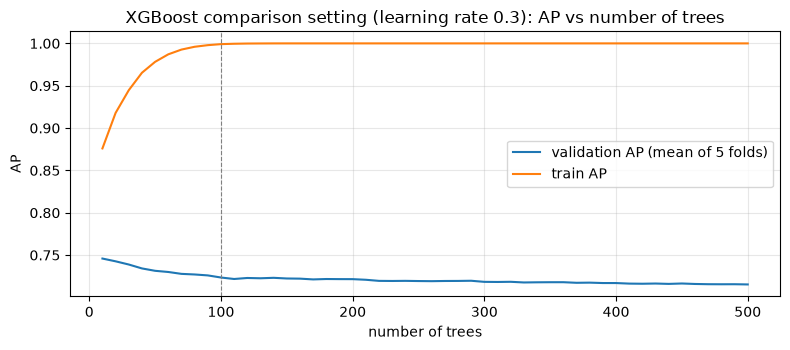

CV AP at the default 100 trees: 0.7235 | best 0.7459 at 10 trees (train AP there 0.8760)


81 candidates x 5 folds in 190s | comparison setting ranks 70


,max_depth,min_child_weight,gamma,subsample,colsample_bytree,reg_alpha,reg_lambda,scale_pos_weight,cat_encoding,selected,engineered,rare,n_estimators,cv_ap,cv_ap_sd,train_ap
0,6,9.0404,2.1960,0.8006,0.8576,0.0042,0.6533,2.3200,onehot,True,False,True,175,0.7561,0.0254,0.8385
1,6,2.8303,1.2538,0.8658,0.9142,0.0494,6.8550,1.0000,onehot,True,True,True,250,0.7558,0.0255,0.8629
2,4,6.1639,2.8518,0.8363,0.9698,0.0622,1.9293,1.0000,onehot,False,False,True,400,0.7558,0.0253,0.8128
3,5,5.6608,0.5313,0.9642,0.8380,4.5652,2.7497,1.0000,onehot,True,True,True,300,0.7549,0.0279,0.8314
4,4,17.2037,2.1340,0.9250,0.8708,5.0723,10.0259,2.3200,onehot,True,False,False,600,0.7543,0.0276,0.8006
5,7,2.3893,1.1114,0.5183,0.9904,0.0299,4.2076,1.0000,onehot,False,False,True,175,0.7539,0.0249,0.8405
6,5,7.7145,2.7573,0.6472,0.6694,0.0020,1.0750,1.0000,ordinal,False,False,True,300,0.7538,0.0242,0.8168
7,4,12.2997,0.1394,0.9042,0.9883,0.0018,39.5131,2.3200,onehot,False,False,False,525,0.7536,0.0282,0.8104


,learning_rate,n_estimators,cv_ap,cv_ap_sd,train_ap
0,0.0200,175,0.7561,0.0254,0.8385
1,0.0100,350,0.7559,0.0252,0.8391
2,0.0500,70,0.7543,0.0247,0.8379


Tuned XGBoost: {'cat_encoding': 'onehot', 'colsample_bytree': 0.8576, 'engineered': False, 'gamma': 2.196, 'max_depth': 6, 'min_child_weight': 9.0404, 'rare': True, 'reg_alpha': 0.0042, 'reg_lambda': 0.6533, 'scale_pos_weight': 2.32, 'selected': True, 'subsample': 0.8006, 'learning_rate': 0.02, 'n_estimators': 175}


In [4]:
neg_pos = (y_train == 0).sum() / (y_train == 1).sum()
_, c = tree_curve_search(make_xgb, [{}], max_trees=500, step=10)
plot_curve(c[0], 'XGBoost comparison setting (learning rate 0.3): AP vs number of trees', 100)

xgb_space = {'max_depth': randint(2, 8), 'min_child_weight': loguniform(1, 40), 'gamma': uniform(0, 3),
             'subsample': uniform(0.5, 0.5), 'colsample_bytree': uniform(0.3, 0.7), 'reg_alpha': loguniform(1e-3, 10),
             'reg_lambda': loguniform(0.5, 50), 'scale_pos_weight': [1.0, round(float(np.sqrt(neg_pos)), 2)],
             'cat_encoding': ['onehot', 'ordinal'], **TRANSFORM_SPACE}
t0 = time.time()
xgb_search, _ = tree_curve_search(make_xgb, [dict(XGB_DEFAULT)] + [{**c, 'learning_rate': 0.02} for c in
                                                                  ParameterSampler(xgb_space, n_iter=80, random_state=SEED)],
                                  max_trees=1000)
print(f'81 candidates x 5 folds in {time.time() - t0:.0f}s | comparison setting ranks {int(xgb_search.index[xgb_search.cand == 0][0]) + 1}')
show(xgb_search, ['max_depth', 'min_child_weight', 'gamma', 'subsample', 'colsample_bytree', 'reg_alpha', 'reg_lambda',
                  'scale_pos_weight', 'cat_encoding', 'selected', 'engineered', 'rare', 'n_estimators', 'cv_ap', 'cv_ap_sd',
                  'train_ap'])

top = {k: v for k, v in xgb_search.loc[0, 'params'].items() if k not in ('n_estimators', 'learning_rate')}
xgb_lr = pd.concat([tree_curve_search(make_xgb, [{**top, 'learning_rate': r}], max_trees=m, step=s)[0]
                    for r, m, s in [(0.01, 2000, 50), (0.02, 1000, 25), (0.05, 500, 10)]]).sort_values('cv_ap', ascending=False)
show(xgb_lr.reset_index(drop=True), ['learning_rate', 'n_estimators', 'cv_ap', 'cv_ap_sd', 'train_ap'])
XGB_TUNED = round_params(xgb_lr.iloc[0]['params'])
print('Tuned XGBoost:', XGB_TUNED)

**Result.**
- **The validation curve confirms the diagnosis.** At learning rate 0.3, validation AP **peaks after only about 10 trees (0.746)** and falls to 0.724 at the default 100 trees, while train AP rises toward 1. The default model keeps fitting noise for 90 more rounds.
- **The comparison setting ranks 70th of 81.** The tuned model reaches **0.756**. It learns slowly (learning rate 0.02, 175 trees) and blocks small, unreliable splits with `min_child_weight` 9 and `gamma` 2.2. It also samples 80 % of the rows and 86 % of the columns for each tree.
- **The class weight (2.32) is part of the best candidate.** It does not change the ranking much, but it shifts the probabilities upward.
- **The learning rate matters little once the number of trees is matched to it:** 0.01 / 0.02 / 0.05 give 0.756 / 0.756 / 0.754.
- **Transformation choices:** the comparison's input selection is kept (without `OperatingSystems`), rare categories are grouped, and **the engineered features are dropped**.
- **This is the largest tuning gain:** +0.033 on fresh folds, better in all 15.

## 4 · KNN

### 4.1 Current setting and its problems

The comparison configuration: **k = 25, distance weighting, Euclidean distance (p = 2), log1p + StandardScaler, one-hot categories at full weight**. CV AP is 0.723 ± 0.027.

| Problem | Effect on performance |
|---|---|
| **k = 25 is a rule-of-thumb value.** | k sets the bias–variance trade-off. A small k gives noisy votes from few neighbors, while a large k pulls every score toward the 16 % base rate. With only 16 % buyers, 25 neighbors contain only about 4 buyers on average, so the scores are coarse. |
| **The relative weight of the input blocks is arbitrary.** Each categorical variable on which two sessions differ adds 2 to their squared distance. | If the context (month, traffic source, visitor type) dominates the distance, the neighbors are sessions with the same context rather than with similar browsing behavior, although the purchase signal lies in the browsing behavior. |
| **The scaler and the distance metric are fixed.** | Long-tailed inputs and many zeros make the choice between standard, robust and min–max scaling, and between Manhattan and Euclidean distance, matter for who counts as a neighbor. |
| `weights='distance'` gives every training point an infinite weight for itself. | Train AP is 1.0 by construction, so only validation AP is informative. |

### 4.2 Tuning direction

A **random search with 80 candidates** over k (15–200), weighting, p ∈ {1, 2} and the transformation choices: log on/off, scaler, **category weight ∈ {1, 0.5, 0.25}**, input selection, engineered features and rare grouping.

In [5]:
knn_space = {'n_neighbors': [15, 25, 35, 45, 55, 65, 75, 90, 105, 120, 150, 200], 'weights': ['uniform', 'distance'],
             'p': [1, 2], 'log': [True, False], 'scaler': ['standard', 'robust', 'minmax'], 'cat_weight': [1.0, 0.5, 0.25],
             **TRANSFORM_SPACE}
t0 = time.time()
knn_search = search(make_knn, [{}] + list(ParameterSampler(knn_space, n_iter=80, random_state=SEED)))
print(f'81 candidates x 5 folds in {time.time() - t0:.0f}s | comparison setting ranks {int(knn_search.index[knn_search.cand == 0][0]) + 1}')
show(knn_search, ['n_neighbors', 'weights', 'p', 'log', 'scaler', 'cat_weight', 'selected', 'engineered', 'rare', 'cv_ap',
                  'cv_ap_sd'], n=10)
display(knn_search[knn_search.cand == 0][['cv_ap', 'cv_ap_sd']].rename(index=lambda _: 'comparison setting'))
KNN_TUNED = knn_search.loc[0, 'params']
print('Tuned KNN:', KNN_TUNED)

81 candidates x 5 folds in 81s | comparison setting ranks 3


,n_neighbors,weights,p,log,scaler,cat_weight,selected,engineered,rare,cv_ap,cv_ap_sd
0,65.0000,uniform,1.0000,True,robust,0.5000,True,False,False,0.7374,0.0242
1,35.0000,distance,1.0000,True,robust,1.0000,True,False,False,0.7347,0.0227
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.7234,0.0275
3,150.0000,distance,2.0000,True,robust,1.0000,False,False,False,0.7216,0.0201
4,120.0000,distance,2.0000,True,robust,1.0000,False,True,False,0.7209,0.0201
5,65.0000,uniform,2.0000,True,robust,0.2500,True,False,True,0.7207,0.0232
6,65.0000,uniform,2.0000,True,robust,0.5000,False,False,True,0.7180,0.0224
7,105.0000,distance,2.0000,True,robust,0.2500,False,False,True,0.7179,0.0211
8,55.0000,uniform,2.0000,True,robust,0.5000,False,False,False,0.7166,0.0248
9,75.0000,distance,1.0000,True,robust,0.5000,True,True,False,0.7165,0.0199


,cv_ap,cv_ap_sd
comparison setting,0.7234,0.0275


Tuned KNN: {'weights': 'uniform', 'selected': True, 'scaler': 'robust', 'rare': False, 'p': 1, 'n_neighbors': 65, 'log': True, 'engineered': False, 'cat_weight': 0.5}


**Result.**
- **The tuned KNN (CV AP 0.737 against 0.723)** uses k = 65 with **uniform** votes and Manhattan distance (p = 1), log1p, **RobustScaler** and a **category weight of 0.5**, on the comparison's selected inputs.
- **RobustScaler appears in all top-10 candidates.** It scales by the inter-quartile range, so sessions with unusual browsing values (for example a high `PageValues`) stay far from typical sessions in the distance.
- **Down-weighting the categories and using Manhattan distance** both reduce how much the session context counts relative to browsing behavior.
- **A larger k smooths the coarse scores:** 65 neighbors contain about 10 buyers on average, against 4 with k = 25.
- **The comparison setting still ranks 3rd.** Most other random combinations are worse, which shows how sensitive KNN is to these choices.
- **Confirmed on fresh folds:** +0.015, better in all 15.

## 5 · LightGBM

### 5.1 Current setting and its problems

The comparison configuration uses LightGBM's defaults: **100 trees, learning_rate 0.1, num_leaves 31 (grown leaf-wise, no depth limit), min_child_samples 20, no sampling, no L1/L2 regularization**, with the 12 engineered features. CV AP is 0.740 ± 0.025, with train AP 0.979.

| Problem | Effect on performance |
|---|---|
| **31 leaves grown leaf-wise with no depth limit, leaves of only 20 sessions, and no regularization.** | LightGBM always splits the leaf with the largest gain, so trees become deep and lopsided and isolate small groups. With about 1.2k buyers per training fold, these leaves fit noise, as train AP 0.979 against CV AP 0.740 shows. |
| **The learning rate and the number of trees are not matched** (0.1 × 100 trees). | Boosting may stop too early or too late. A validation curve checks which. |
| **No row or column sampling.** | A cheap regularizer is not used. |

### 5.2 Tuning direction

The same three steps as for XGBoost, with **80 random candidates** that put more weight on smaller trees (num_leaves 4–48), larger minimum leaves (up to 200 sessions), `min_split_gain` and L1/L2, plus the transformation choices.

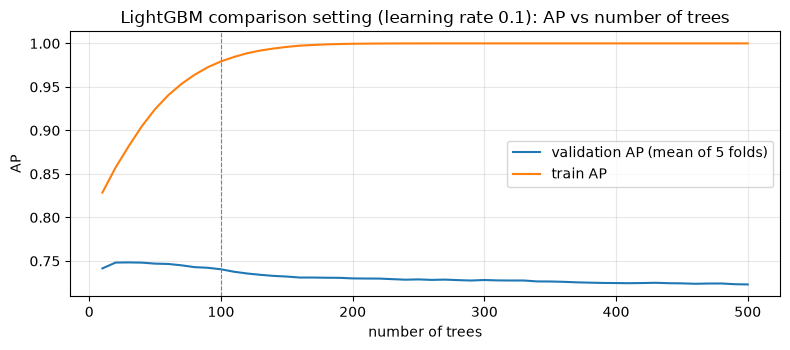

CV AP at the default 100 trees: 0.7404 | best 0.7483 at 30 trees (train AP there 0.8820)


81 candidates x 5 folds in 895s | comparison setting ranks 35


,num_leaves,max_depth,min_child_samples,min_split_gain,subsample,colsample_bytree,reg_alpha,reg_lambda,scale_pos_weight,cat_encoding,selected,engineered,rare,n_estimators,cv_ap,cv_ap_sd,train_ap
0,38,-1,100,0.4833,0.9256,0.9672,2.5825,0.1228,1.0000,onehot,False,False,True,275,0.7539,0.0253,0.8244
1,42,4,20,0.4532,0.5282,0.8440,0.0934,0.0110,2.3200,onehot,False,True,True,250,0.7534,0.0274,0.8226
2,42,5,100,0.0697,0.7994,0.5200,0.1443,0.0564,1.0000,onehot,False,True,False,275,0.7531,0.0279,0.8290
3,24,4,75,0.3038,0.9042,0.9883,0.0018,32.3519,2.3200,onehot,False,False,False,450,0.7530,0.0258,0.8015
4,39,-1,75,0.2398,0.7822,0.7754,0.8857,1.1563,2.3200,onehot,True,False,False,200,0.7528,0.0256,0.8424
5,18,8,150,0.0202,0.9479,0.8325,0.0028,0.4218,1.0000,onehot,True,True,False,250,0.7527,0.0289,0.8318
6,29,5,150,0.0568,0.9261,0.8299,0.1206,7.1909,1.0000,onehot,False,True,True,375,0.7526,0.0283,0.8234
7,39,5,10,0.4017,0.8658,0.7403,0.0494,1.2675,1.0000,ordinal,True,False,True,225,0.7524,0.0249,0.8485


,learning_rate,n_estimators,cv_ap,cv_ap_sd,train_ap
0,0.0100,350,0.7542,0.0253,0.8060
1,0.0200,275,0.7539,0.0253,0.8244
2,0.0500,90,0.7532,0.0262,0.8167


Tuned LightGBM: {'cat_encoding': 'onehot', 'colsample_bytree': 0.9672, 'engineered': False, 'max_depth': -1, 'min_child_samples': 100, 'min_split_gain': 0.4833, 'num_leaves': 38, 'rare': True, 'reg_alpha': 2.5825, 'reg_lambda': 0.1228, 'scale_pos_weight': 1.0, 'selected': False, 'subsample': 0.9256, 'learning_rate': 0.01, 'n_estimators': 350}


In [6]:
_, c = tree_curve_search(make_lgbm, [{}], max_trees=500, step=10)
plot_curve(c[0], 'LightGBM comparison setting (learning rate 0.1): AP vs number of trees', 100)

lgbm_space = {'num_leaves': randint(4, 49), 'max_depth': [-1, 3, 4, 5, 6, 8],
              'min_child_samples': [10, 20, 30, 50, 75, 100, 150, 200], 'min_split_gain': uniform(0, 0.5),
              'subsample': uniform(0.5, 0.5), 'colsample_bytree': uniform(0.3, 0.7), 'reg_alpha': loguniform(1e-3, 10),
              'reg_lambda': loguniform(1e-2, 50), 'scale_pos_weight': [1.0, round(float(np.sqrt(neg_pos)), 2)],
              'cat_encoding': ['onehot', 'ordinal'], **TRANSFORM_SPACE}
t0 = time.time()
lgbm_search, _ = tree_curve_search(make_lgbm, [dict(LGBM_DEFAULT)] + [{**c, 'learning_rate': 0.02} for c in
                                                                     ParameterSampler(lgbm_space, n_iter=80, random_state=SEED)],
                                   max_trees=1000)
print(f'81 candidates x 5 folds in {time.time() - t0:.0f}s | comparison setting ranks {int(lgbm_search.index[lgbm_search.cand == 0][0]) + 1}')
show(lgbm_search, ['num_leaves', 'max_depth', 'min_child_samples', 'min_split_gain', 'subsample', 'colsample_bytree',
                   'reg_alpha', 'reg_lambda', 'scale_pos_weight', 'cat_encoding', 'selected', 'engineered', 'rare',
                   'n_estimators', 'cv_ap', 'cv_ap_sd', 'train_ap'])

top = {k: v for k, v in lgbm_search.loc[0, 'params'].items() if k not in ('n_estimators', 'learning_rate')}
lgbm_lr = pd.concat([tree_curve_search(make_lgbm, [{**top, 'learning_rate': r}], max_trees=m, step=s)[0]
                     for r, m, s in [(0.01, 2000, 50), (0.02, 1000, 25), (0.05, 500, 10)]]).sort_values('cv_ap', ascending=False)
show(lgbm_lr.reset_index(drop=True), ['learning_rate', 'n_estimators', 'cv_ap', 'cv_ap_sd', 'train_ap'])
LGBM_TUNED = round_params(lgbm_lr.iloc[0]['params'])
print('Tuned LightGBM:', LGBM_TUNED)

**Result.**
- **The validation curve shows early overfitting.** At learning rate 0.1, validation AP peaks after **about 30 trees (0.748)** and declines to 0.740 at the default 100 trees.
- **The comparison setting ranks 35th of 81.** The tuned model (CV AP 0.754) uses **at least 100 sessions per leaf** (instead of 20) and a minimum split gain of 0.48. It adds an L1 penalty of 2.6 and learns slowly (learning rate 0.01, 350 trees). Train AP falls from 0.98 to 0.81.
- **The search favors this kind of regularization:** all of the top 8 candidates use at least 75 sessions per leaf or depth ≤ 5.
- **Transformation choices:** rare categories are grouped, and the engineered features are dropped (the comparison had kept them).
- **The gain on fresh folds is modest:** +0.006, better in 11/15 folds.

## 6 · Neural Network (MLP)

### 6.1 Current setting and its problems

The comparison configuration: **two hidden layers (64, 32), ReLU, L2 penalty `alpha` = 0.0001, Adam with learning rate 0.001, batch size 200, early stopping on 10 % of the training fold**. CV AP is 0.740, but with the **largest fold SD of all models (0.033)**.

| Problem | Effect on performance |
|---|---|
| **Almost no weight penalty** (`alpha` = 1e-4) for a network with several thousand weights trained on about 7,800 sessions. | The network can fit noise. Early stopping is its only protection, and early stopping depends on a small random validation split. That is why the results vary so much from fold to fold. |
| **The architecture is a fixed guess** (64, 32). | Too large a network overfits, while too small a one cannot represent the interactions, such as `PageValues` × `Month`. |
| **The learning rate and batch size are defaults.** | They decide how noisy the training is and where early stopping stops, so they affect both the level and the stability of AP. |
| **The input scaling is fixed** (log1p + standard scaling). | Neural networks train best with well-scaled inputs, so the scaler choice matters. |

### 6.2 Tuning direction

A **random search with 50 candidates** over the architecture (one or two layers, 16–128 units), `alpha` (1e-5 to 1, log scale), learning rate, batch size, activation, and the transformation choices: log on/off, scaler, input selection, engineered features and rare grouping. A smaller budget suffices here because the space has fewer parameters that matter.

In [7]:
mlp_space = {'hidden_layer_sizes': [(16,), (32,), (64,), (128,), (32, 16), (64, 32), (128, 64)],
             'alpha': loguniform(1e-5, 1), 'learning_rate_init': loguniform(1e-4, 1e-2), 'batch_size': [64, 128, 256],
             'activation': ['relu', 'tanh'], 'log': [True, False], 'scaler': ['standard', 'robust', 'minmax'],
             **TRANSFORM_SPACE}
t0 = time.time()
mlp_search = search(make_mlp, [{}] + list(ParameterSampler(mlp_space, n_iter=50, random_state=SEED)))
print(f'51 candidates x 5 folds in {time.time() - t0:.0f}s | comparison setting ranks {int(mlp_search.index[mlp_search.cand == 0][0]) + 1}')
show(mlp_search, ['hidden_layer_sizes', 'alpha', 'learning_rate_init', 'batch_size', 'activation', 'log', 'scaler',
                  'selected', 'engineered', 'rare', 'cv_ap', 'cv_ap_sd', 'train_ap'], n=10)
display(mlp_search[mlp_search.cand == 0][['cv_ap', 'cv_ap_sd', 'train_ap']].rename(index=lambda _: 'comparison setting'))
MLP_TUNED = round_params(mlp_search.loc[0, 'params'])
print('Tuned MLP:', MLP_TUNED)

51 candidates x 5 folds in 73s | comparison setting ranks 1


,hidden_layer_sizes,alpha,learning_rate_init,batch_size,activation,log,scaler,selected,engineered,rare,cv_ap,cv_ap_sd,train_ap
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.7400,0.0325,0.7803
1,"(128,)",0.0288,0.0027,64.0000,tanh,True,standard,False,False,True,0.7360,0.0290,0.7570
2,"(128, 64)",0.0643,0.0040,256.0000,relu,True,robust,False,False,True,0.7354,0.0229,0.7919
3,"(128, 64)",0.0000,0.0003,64.0000,relu,True,robust,True,False,True,0.7352,0.0224,0.7586
4,"(128, 64)",0.0005,0.0022,128.0000,relu,True,robust,True,True,False,0.7347,0.0334,0.8226
5,"(32,)",0.0058,0.0042,128.0000,tanh,True,standard,False,False,True,0.7303,0.0125,0.7724
6,"(128, 64)",0.0006,0.0010,64.0000,tanh,True,standard,False,True,True,0.7294,0.0314,0.7673
7,"(16,)",0.3059,0.0019,128.0000,tanh,True,robust,False,True,False,0.7284,0.0319,0.7423
8,"(128, 64)",0.1026,0.0007,64.0000,relu,True,minmax,True,False,True,0.7266,0.0198,0.7579
9,"(16,)",0.0002,0.0021,128.0000,relu,True,standard,True,True,False,0.7255,0.0260,0.7690


,cv_ap,cv_ap_sd,train_ap
comparison setting,0.7400,0.0325,0.7803


Tuned MLP: {}


**Result.**
- **The comparison setting ranks first of 51 candidates (CV AP 0.740),** so it is kept unchanged.
- **Some alternatives are more stable but score lower.** For example, (128, 64) units with a stronger L2 penalty (0.064) and RobustScaler has a fold SD of 0.023 instead of 0.033, but a mean AP of only 0.735.
- **The suspected problem was real but costs little.** Instability from the weak weight penalty is real, but stronger penalties also lowered the mean AP in this budget.
- **The network's main value is diversity.** Its scores are the least correlated with the tree models (0.88–0.90), which is why it stays useful in the ensemble despite a slightly lower single score.

## 7 · Ensembles and Final Model Selection (15 fresh folds)

Each tuned setting won a search on the team's 5 folds, so its score there is optimistic. All candidates are therefore re-evaluated on **15 new folds** (3 × 5-fold, seed 2026) that took no part in tuning:

- each shortlisted model at its **comparison** ("before") and **tuned** setting;
- **soft voting**, which averages the probabilities of the tuned models. The versions are all five models and the three best tuned models;
- **stacking**, where a logistic regression learns how to weight the tuned models' out-of-fold probabilities. It is fitted on 4 folds and scored on the 5th, so the stacker is cross-validated too.

**Selection rule (fixed in advance):** take the candidate with the highest mean AP. If a *simpler* candidate is within one standard error of the paired fold differences (single model < averaging < stacking), take the simpler one.

In [8]:
TUNED = {'Random forest': RF_TUNED, 'XGBoost': XGB_TUNED, 'KNN': KNN_TUNED, 'LightGBM': LGBM_TUNED,
         'Neural network (MLP)': MLP_TUNED}
short = lambda m: m.split(' (')[0].lower().replace(' ', '_')


def build(name, include_pv=True):
    if name.startswith(('Average', 'Stacking')):
        members = [(short(m), build(f'{m} (tuned)', include_pv)) for m in name.split(': ')[1].split(' + ')]
        if name.startswith('Average'):
            return VotingClassifier(members, voting='soft')
        return StackingClassifier(members, final_estimator=LogisticRegression(max_iter=1000), stack_method='predict_proba',
                                  cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
    model, version = name.rsplit(' (', 1)
    if model == 'Neural network':
        model, version = 'Neural network (MLP)', name.rsplit(' (', 1)[1]
    params = {} if version == 'before)' else TUNED[model]
    return FACTORY[model](**params, include_pv=include_pv)


t0 = time.time()
OOF = {f'{m} ({v})': repeated_oof(build(f'{m} ({v})')) for m in MODELS for v in ['before', 'tuned']}
print(f'10 single settings x 15 folds in {time.time() - t0:.0f}s')


def stack_oof(members):
    out = np.full_like(OOF[f'{members[0]} (tuned)'], np.nan)
    for r in range(out.shape[0]):
        Z = np.column_stack([OOF[f'{m} (tuned)'][r] for m in members])
        for j in range(5):
            tr, va = CONFIRM_FOLDS[r * 5 + j]
            out[r, va] = LogisticRegression(max_iter=1000).fit(Z[tr], y_train[tr]).predict_proba(Z[va])[:, 1]
    return out


tuned_rank = sorted(MODELS, key=lambda m: -fold_aps(OOF[f'{m} (tuned)']).mean())
for members in [MODELS, tuned_rank[:3]]:
    OOF['Average: ' + ' + '.join(members)] = np.mean([OOF[f'{m} (tuned)'] for m in members], axis=0)
    OOF['Stacking: ' + ' + '.join(members)] = stack_oof(members)

FOLD_AP = {n: fold_aps(o) for n, o in OOF.items()}
complexity = lambda n: 2 if n.startswith('Stacking') else 1 if n.startswith('Average') else 0
best_name = max(FOLD_AP, key=lambda n: FOLD_AP[n].mean())
rows = []
for n, a in FOLD_AP.items():
    d = a - FOLD_AP[best_name]
    rows.append({'candidate': n, 'kind': ['single', 'average', 'stacking'][complexity(n)], 'AP (15 folds)': a.mean(),
                 'SD': a.std(ddof=1), 'diff vs best': d.mean(), 'SE of diff': d.std(ddof=1) / np.sqrt(len(d)),
                 'folds better than best': f'{(d > 0).sum()}/{len(d)}'})
selection = pd.DataFrame(rows).set_index('candidate').sort_values('AP (15 folds)', ascending=False)
eligible = selection[selection['diff vs best'] >= -selection['SE of diff']]
FINAL_NAME = min(eligible.index, key=lambda n: (complexity(n), -selection.loc[n, 'AP (15 folds)']))
display(selection)
print('Highest mean AP:', best_name, '| eligible under the 1-SE rule:', list(eligible.index))
print('FINAL MODEL:', FINAL_NAME)
selection.to_csv(OUT / 'final_selection_15_folds.csv')

10 single settings x 15 folds in 35s


,kind,AP (15 folds),SD,diff vs best,SE of diff,folds better than best
candidate,,,,,,
Stacking: Random forest + XGBoost + KNN + LightGBM + Neural network (MLP),stacking,0.7573,0.0134,0.0000,0.0000,0/15
Average: Random forest + XGBoost + KNN + LightGBM + Neural network (MLP),average,0.7565,0.0126,-0.0007,0.0007,4/15
Stacking: XGBoost + Random forest + LightGBM,stacking,0.7563,0.0128,-0.0010,0.0005,6/15
Average: XGBoost + Random forest + LightGBM,average,0.7559,0.0130,-0.0013,0.0007,4/15
XGBoost (tuned),single,0.7543,0.0132,-0.0030,0.0007,1/15
Random forest (tuned),single,0.7540,0.0132,-0.0032,0.0009,2/15
LightGBM (tuned),single,0.7518,0.0135,-0.0055,0.0010,1/15
Random forest (before),single,0.7471,0.0122,-0.0102,0.0018,1/15
LightGBM (before),single,0.7454,0.0158,-0.0119,0.0026,2/15


Highest mean AP: Stacking: Random forest + XGBoost + KNN + LightGBM + Neural network (MLP) | eligible under the 1-SE rule: ['Stacking: Random forest + XGBoost + KNN + LightGBM + Neural network (MLP)']
FINAL MODEL: Stacking: Random forest + XGBoost + KNN + LightGBM + Neural network (MLP)


,before,tuned,gain,SD of gain,folds improved
Random forest,0.7471,0.7540,0.0069,0.0063,14/15
XGBoost,0.7213,0.7543,0.0330,0.0112,15/15
KNN,0.7207,0.7360,0.0153,0.0092,15/15
LightGBM,0.7454,0.7518,0.0064,0.0105,11/15
Neural network (MLP),0.7295,0.7295,0.0000,0.0000,0/15


,Random forest,XGBoost,KNN,LightGBM,Neural network (MLP)
Random forest,1.0000,0.9585,0.9139,0.9459,0.8987
XGBoost,0.9585,1.0000,0.8903,0.9782,0.8847
KNN,0.9139,0.8903,1.0000,0.8791,0.8529
LightGBM,0.9459,0.9782,0.8791,1.0000,0.8800
Neural network (MLP),0.8987,0.8847,0.8529,0.8800,1.0000


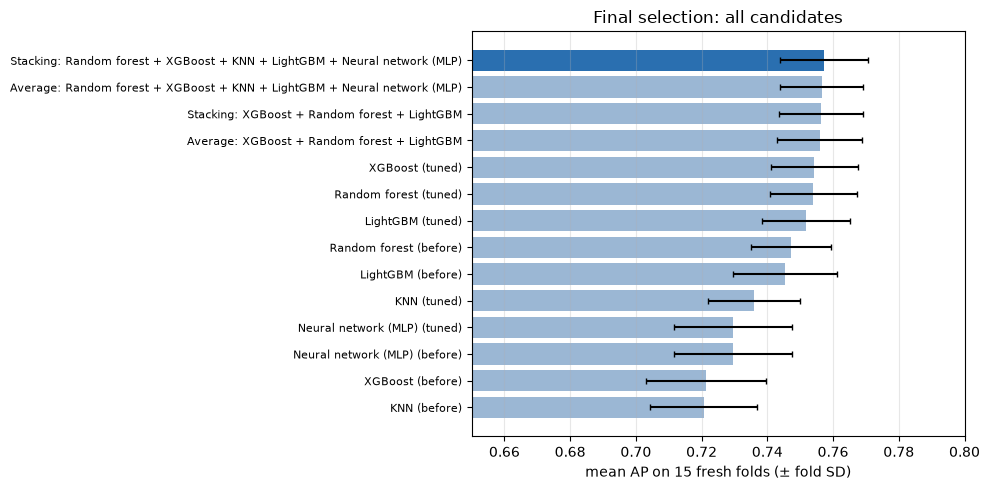

In [9]:
gain = pd.DataFrame({m: {'before': FOLD_AP[f'{m} (before)'].mean(), 'tuned': FOLD_AP[f'{m} (tuned)'].mean(),
                         'gain': (FOLD_AP[f'{m} (tuned)'] - FOLD_AP[f'{m} (before)']).mean(),
                         'SD of gain': (FOLD_AP[f'{m} (tuned)'] - FOLD_AP[f'{m} (before)']).std(ddof=1),
                         'folds improved': f"{(FOLD_AP[f'{m} (tuned)'] > FOLD_AP[f'{m} (before)']).sum()}/15"}
                     for m in MODELS}).T
display(gain)
gain.to_csv(OUT / 'tuning_gain_15_folds.csv')
corr = pd.DataFrame({m: OOF[f'{m} (tuned)'].ravel() for m in MODELS}).corr(method='spearman')
display(corr)

fig, ax = plt.subplots(figsize=(10, 5))
order = selection.index[::-1]
ax.barh(order, selection.loc[order, 'AP (15 folds)'], xerr=selection.loc[order, 'SD'], capsize=2,
        color=['#2a6fb0' if n == FINAL_NAME else '#9bb7d4' for n in order])
ax.set(xlim=(0.65, 0.8), xlabel='mean AP on 15 fresh folds (± fold SD)', title='Final selection: all candidates')
ax.tick_params(axis='y', labelsize=8); ax.grid(alpha=.3, axis='x')
fig.tight_layout(); fig.savefig(OUT / 'final_selection.png', dpi=150); plt.show()

**Result.**
- **Tuning gains on fresh folds:**
  - XGBoost **+0.033 (15/15)**;
  - KNN **+0.015 (15/15)**;
  - random forest **+0.007 (14/15)**;
  - LightGBM +0.006 (11/15);
  - neural network unchanged.

  On these fresh folds, the best single models are tuned XGBoost (0.754) and tuned random forest (0.754).
- **Ensembles add a little on top:**

  | Candidate | AP (15 folds) |
  |---|---|
  | **Stacking of all five** | **0.7573** |
  | Averaging all five | 0.7565 |
  | Stacking the three trees | 0.7563 |
  | Averaging the three trees | 0.7559 |
  | Tuned XGBoost (best single model) | 0.7543 |

- **Why the gain is small.** The tuned models' scores are highly correlated (Spearman 0.85–0.98), so they disagree on few sessions. The two less correlated models, KNN and the neural network, are what lift the five-model stack above the three-tree versions.
- **The rule selects stacking of all five.** No simpler candidate is within one standard error of it. The averaging ensemble misses by a hair (difference 0.0007, about one SE) and would be an almost equally good, simpler alternative.

## 8 · Final Model: Refit on All Training Data and Fix the Threshold

The final model is refitted on **all 9,764 training sessions**. The decision threshold is fixed before the test set is read: it maximizes F1 on the pooled out-of-fold probabilities of the 15 fresh folds. F1 balances missed buyers against false alarms. A cost-based threshold would replace it once the business costs are known.

In [10]:
final_model = build(FINAL_NAME).fit(X_train, y_train)
pooled_y = np.concatenate([y_train] * OOF[FINAL_NAME].shape[0])
prec, rec, thr = precision_recall_curve(pooled_y, OOF[FINAL_NAME].ravel())
f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
FINAL_THRESHOLD = float(thr[np.nanargmax(f1)])
cv_estimate = selection.loc[FINAL_NAME]
print(f'Final model: {FINAL_NAME}')
print(f'CV estimate of AP (15 fresh folds): {cv_estimate["AP (15 folds)"]:.4f} ± {cv_estimate["SD"]:.4f}')
print(f'Decision threshold (max F1 on OOF): {FINAL_THRESHOLD:.3f} '
      f'(OOF precision {prec[np.nanargmax(f1)]:.3f}, recall {rec[np.nanargmax(f1)]:.3f}, F1 {np.nanmax(f1):.3f})')

Final model: Stacking: Random forest + XGBoost + KNN + LightGBM + Neural network (MLP)
CV estimate of AP (15 fresh folds): 0.7573 ± 0.0134
Decision threshold (max F1 on OOF): 0.373 (OOF precision 0.675, recall 0.702, F1 0.688)


## 9 · Generalization Error on the Test Set (run once)

This is the only cell that reads `test_raw.csv`. The model, its hyperparameters and its threshold are fixed above, and nothing is changed afterwards. There are two baselines, neither of which needs fitting on the test set: a dummy that predicts the purchase rate, and the one-line rule "rank sessions by `PageValues`". The 95 % intervals come from 1,000 bootstrap resamples of the test sessions.

,AP,ROC-AUC,threshold,Precision,Recall,F1,Accuracy,TN,FP,FN,TP
Dummy (purchase rate),0.1565,0.5000,0.5000,0.0000,0.0000,0.0000,0.8435,2059.0000,0.0000,382.0000,0.0000
Rule: rank by PageValues,0.6215,0.8659,0.0000,0.5709,0.8115,0.6703,0.8751,1826.0000,233.0000,72.0000,310.0000
Final model: Stacking: Random forest + XGBoost + KNN + LightGBM + Neural network (MLP),0.7620,0.9379,0.3730,0.6878,0.7094,0.6985,0.9041,1936.0000,123.0000,111.0000,271.0000


,test,ci95_low,ci95_high,CV estimate (15 folds)
AP,0.7620,0.7211,0.8041,0.7573
ROC-AUC,0.9379,0.9263,0.9488,NaN
Precision,0.6878,0.6437,0.7337,NaN
Recall,0.7094,0.6666,0.7572,NaN
F1,0.6985,0.6620,0.7354,NaN


At threshold 0.5 instead: {'Precision': 0.7171, 'Recall': 0.6571, 'F1': 0.6858, 'Accuracy': 0.9058, 'TN': 1960.0, 'FP': 99.0, 'FN': 131.0, 'TP': 251.0}


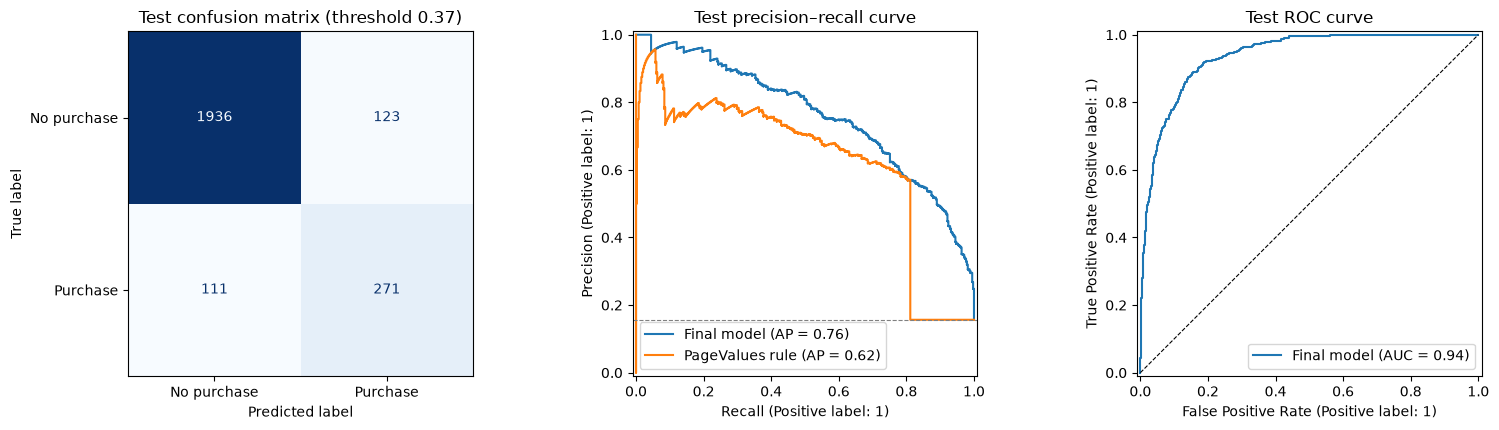

In [11]:
assert not TEST_EVALUATED, 'The test set has already been used. Do not re-run or tune after this point.'
test_raw = pd.read_csv('test_raw.csv')
X_test, y_test = test_raw[FEATURES], test_raw[TARGET].astype(int).to_numpy()
assert not set(train_raw['source_row_id']) & set(test_raw['source_row_id'])
TEST_EVALUATED = True

p_final = final_model.predict_proba(X_test)[:, 1]
scores = {'Dummy (purchase rate)': np.full(len(y_test), y_train.mean()),
          'Rule: rank by PageValues': X_test['PageValues'].to_numpy(), f'Final model: {FINAL_NAME}': p_final}
cutoffs = {'Dummy (purchase rate)': 0.5, 'Rule: rank by PageValues': 1e-9, f'Final model: {FINAL_NAME}': FINAL_THRESHOLD}


def threshold_metrics(y, p, t):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {'Precision': precision_score(y, pred, zero_division=0), 'Recall': recall_score(y, pred),
            'F1': f1_score(y, pred, zero_division=0), 'Accuracy': accuracy_score(y, pred), 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp}


test_table = pd.DataFrame({n: {'AP': ap(y_test, p), 'ROC-AUC': roc_auc_score(y_test, p), 'threshold': cutoffs[n],
                               **threshold_metrics(y_test, p, cutoffs[n])} for n, p in scores.items()}).T
display(test_table)

rng = np.random.default_rng(SEED)
boot = defaultdict(list)
for _ in range(1000):
    i = rng.integers(0, len(y_test), len(y_test))
    m = threshold_metrics(y_test[i], p_final[i], FINAL_THRESHOLD)
    boot['AP'].append(ap(y_test[i], p_final[i])); boot['ROC-AUC'].append(roc_auc_score(y_test[i], p_final[i]))
    for k in ['Precision', 'Recall', 'F1']:
        boot[k].append(m[k])
ci = pd.DataFrame({k: {'test': test_table.loc[f'Final model: {FINAL_NAME}', k], 'ci95_low': np.percentile(v, 2.5),
                       'ci95_high': np.percentile(v, 97.5)} for k, v in boot.items()}).T
ci.loc['AP', 'CV estimate (15 folds)'] = cv_estimate['AP (15 folds)']
display(ci)
print('At threshold 0.5 instead:', {k: round(float(v), 4) for k, v in threshold_metrics(y_test, p_final, 0.5).items()})
test_table.to_csv(OUT / 'final_test_results.csv'); ci.to_csv(OUT / 'final_test_ci.csv')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
ConfusionMatrixDisplay(confusion_matrix(y_test, (p_final >= FINAL_THRESHOLD).astype(int)),
                       display_labels=['No purchase', 'Purchase']).plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title(f'Test confusion matrix (threshold {FINAL_THRESHOLD:.2f})')
PrecisionRecallDisplay.from_predictions(y_test, p_final, ax=axes[1], name='Final model')
PrecisionRecallDisplay.from_predictions(y_test, scores['Rule: rank by PageValues'], ax=axes[1], name='PageValues rule')
axes[1].axhline(y_test.mean(), ls='--', c='grey', lw=.8); axes[1].set_title('Test precision–recall curve')
RocCurveDisplay.from_predictions(y_test, p_final, ax=axes[2], name='Final model')
axes[2].plot([0, 1], [0, 1], 'k--', lw=.8); axes[2].set_title('Test ROC curve')
fig.tight_layout(); fig.savefig(OUT / 'final_test_curves.png', dpi=150); plt.show()

**Result.**
- **Generalization error.** The final model reaches **test AP 0.762 (95 % CI 0.721–0.804)** and ROC-AUC 0.938. The 15-fold CV estimate of 0.757 lies well inside this interval, so it was reliable.
- **Against the baselines:**
  - **Dummy:** AP 0.156, and it never finds a buyer.
  - **Ranking by `PageValues` alone:** AP 0.622. The model adds +0.14 AP. At the chosen thresholds, it makes **123 false alarms instead of 233** and is right more often when it flags a session (precision 69 % against 57 %). It finds fewer buyers (71 % against 81 %).
- **At the training-chosen threshold of 0.373,** the model finds **271 of the 382 buyers (recall 71 %)**. **69 % of the sessions it flags actually buy**, giving F1 0.699 and accuracy 0.904.
- **At 0.5** (the team default), precision is 72 % and recall 66 %, with F1 0.686. Which threshold is better depends on the cost of an offer versus the value of a purchase.

## 10 · Explaining the Final Model

The model is fixed. These analyses describe it but do not change it:

1. **Components and weights.**
2. **Permutation importance** of the 17 raw inputs on a training validation fold, so the test set is not used.
3. **`PageValues` dependence:** the same final configuration, cross-validated without `PageValues` and without re-tuning.

Final model: Stacking: Random forest + XGBoost + KNN + LightGBM + Neural network (MLP)
Stacking weights: {'random_forest': np.float64(1.426), 'xgboost': np.float64(4.194), 'knn': np.float64(0.336), 'lightgbm': np.float64(-0.483), 'neural_network': np.float64(1.195)}
  Random forest: {'selected': False, 'rare': True, 'min_samples_leaf': 20, 'max_samples': 0.6, 'max_features': 0.3, 'max_depth': 10, 'engineered': False, 'criterion': 'entropy', 'class_weight': None, 'cat_encoding': 'onehot', 'n_estimators': 500}
  XGBoost: {'cat_encoding': 'onehot', 'colsample_bytree': 0.8576, 'engineered': False, 'gamma': 2.196, 'max_depth': 6, 'min_child_weight': 9.0404, 'rare': True, 'reg_alpha': 0.0042, 'reg_lambda': 0.6533, 'scale_pos_weight': 2.32, 'selected': True, 'subsample': 0.8006, 'learning_rate': 0.02, 'n_estimators': 175}
  KNN: {'weights': 'uniform', 'selected': True, 'scaler': 'robust', 'rare': False, 'p': 1, 'n_neighbors': 65, 'log': True, 'engineered': False, 'cat_weight': 0.5}
  LightGBM

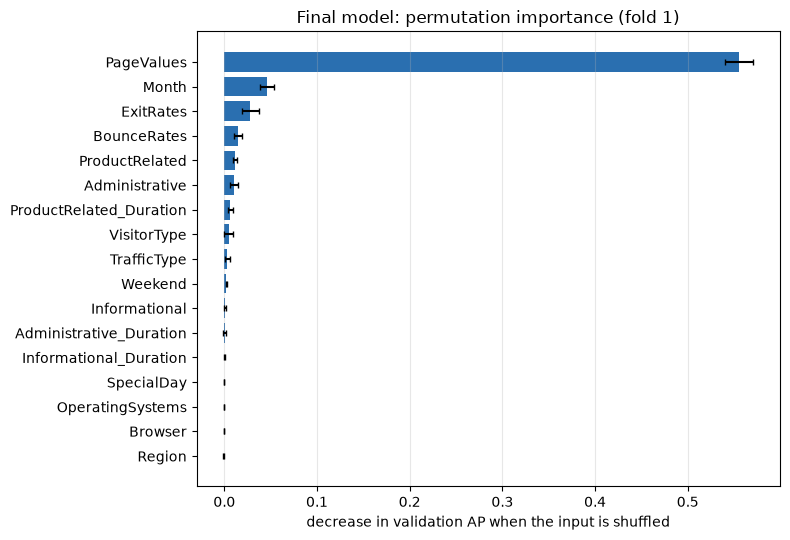

,AP drop,SD
PageValues,0.5555,0.0154
Month,0.0462,0.0074
ExitRates,0.0282,0.0089
BounceRates,0.0148,0.0043
ProductRelated,0.0117,0.0020
Administrative,0.0105,0.0046
ProductRelated_Duration,0.0064,0.0029
VisitorType,0.0047,0.0045


,AP,ROC-AUC,Train AP
with PageValues,0.7582,0.9341,0.8242
without PageValues (same settings),0.3840,0.7780,0.5041


In [12]:
print('Final model:', FINAL_NAME)
if hasattr(final_model, 'final_estimator_'):
    print('Stacking weights:', dict(zip([n for n, _ in final_model.estimators], final_model.final_estimator_.coef_.ravel().round(3))))
members = FINAL_NAME.split(': ')[1].split(' + ') if ': ' in FINAL_NAME else [FINAL_NAME.rsplit(' (', 1)[0]]
for m in members:
    print(f'  {m}:', TUNED.get(m, TUNED.get(m + ' (MLP)', {})))

tr, va = FOLDS[0]
fold_model = build(FINAL_NAME).fit(X_train.iloc[tr], y_train[tr])
imp = permutation_importance(fold_model, X_train.iloc[va], y_train[va], scoring='average_precision', n_repeats=5,
                             random_state=SEED, n_jobs=1)
importance = pd.DataFrame({'AP drop': imp.importances_mean, 'SD': imp.importances_std}, index=FEATURES).sort_values('AP drop')
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(importance.index, importance['AP drop'], xerr=importance['SD'], capsize=2, color='#2a6fb0')
ax.set(xlabel='decrease in validation AP when the input is shuffled', title='Final model: permutation importance (fold 1)')
ax.grid(alpha=.3, axis='x'); fig.tight_layout(); fig.savefig(OUT / 'final_permutation_importance.png', dpi=150); plt.show()
display(importance.sort_values('AP drop', ascending=False).head(8))

with_pv, without_pv = fold_scores(build(FINAL_NAME)), fold_scores(build(FINAL_NAME, include_pv=False))
display(pd.DataFrame({'with PageValues': with_pv.mean(), 'without PageValues (same settings)': without_pv.mean()}).T)

**Result.**
- **How the final model works.** The five tuned models each give a probability, and a logistic regression combines them:

  | Member | Stacking weight |
  |---|---|
  | XGBoost | 4.19 |
  | Random forest | 1.43 |
  | Neural network | 1.20 |
  | KNN | 0.34 |
  | LightGBM | −0.48 |

  LightGBM's weight is negative because its scores almost duplicate XGBoost's (correlation 0.98), so the stacker uses it as a small correction. Its contribution should not be read on its own.
- **What drives the predictions.** **`PageValues` dominates: shuffling it lowers AP by 0.56.**
  - Next come `Month` (0.046), `ExitRates` (0.028), `BounceRates` (0.015) and the product and administrative page counts.
  - Region, browser, operating system and weekend contribute almost nothing.
  - This matches the comparison notebook and the individual model notebooks.
- **`PageValues` dependence.** With the same settings but without `PageValues`, CV AP falls from 0.758 to **0.384** (ROC-AUC 0.934 → 0.778). The model is still 2.5 times better than random, but half of its performance rests on this one variable.
- These are associations in observational data. They do not show that changing a feature would cause purchases.

## 11 · Assumptions and Limitations

| # | Assumption or limitation | Likely impact | How it could be addressed |
|---|---|---|---|
| 1 | **`PageValues` is assumed to be available at prediction time and free of leakage.** It is not a copy of the outcome (19.5 % of buyers have value 0), but the Google Analytics page values were probably computed over the same period, which includes the sessions' own purchases. | If it leaks, performance is overstated by about a factor of two (AP 0.76 with it against 0.38 without). The realistic performance of a deployed model would be closer to the lower figure. | Ask the data owner how, and over which window, page values were computed. Rebuild `PageValues` from an **earlier period only** (a historical lookup per page). Report the without-`PageValues` model as a lower bound, as in §10. |
| 2 | **The test set is not fully fresh.** It was used in the individual model notebooks and by an earlier version of this notebook, which evaluated a different final model. | Team decisions taken with test results in view, such as keeping `PageValues`, may make the test score slightly optimistic. The close agreement with the 15-fold CV estimate (0.757 against 0.762) suggests the effect is small. | Report the CV estimate as the main number. Hold out a new test sample, for example later sessions, for a final confirmation. |
| 3 | **Sessions are assumed to be independent and representative of future traffic** (random split of one year). | Repeat visitors may appear in both training and test data, and seasonal patterns can shift, so future performance may be lower. | Validate **by time** (train on earlier months, test on later ones) and **by user** once visitor IDs exist. Monitor after deployment. |
| 4 | **Features describe the complete session.** | The model can only score a session after it ends, so it cannot yet trigger an intervention during the visit. | Rebuild the features from partial sessions (first n pages or minutes) using clickstream data, and retrain. |
| 5 | **The decision threshold maximizes F1, not profit.** | The numbers of missed buyers and false alarms may not match the business optimum. | Define the value of a purchase and the cost of an offer, and choose the threshold that maximizes expected profit on out-of-fold predictions. |
| 6 | **Finite search budgets** (51–81 random candidates per model). | Better settings may exist. The team-fold scores of the winners are optimistic, which is why fresh folds were used for selection. | Larger budgets or Bayesian optimization, and nested CV for an unbiased tuning estimate. |
| 7 | **The ensemble is complex for a small gain** (+0.003 AP over tuned XGBoost), and the stacking weights of correlated members (for example LightGBM's −0.48) are not interpretable on their own. | Five models are harder to maintain, explain and monitor than one. | If simplicity matters more, use the tuned XGBoost or the averaging ensemble, which are within about 0.003 AP. Explain the model with permutation importance or SHAP rather than the stacking weights. |
| 8 | **Probabilities are not calibrated** beyond the logistic stacker. | Scores can be read as rankings but not necessarily as exact purchase probabilities. | Check a reliability curve and calibrate on out-of-fold predictions (Platt or isotonic) if probabilities are used directly. |
| 9 | **Information that explains many errors is missing** (cart and checkout events, prices, customer history). | Some buyers and non-buyers look identical in the data, so no model can separate them. | Collect the event-level data listed in `model_comparison.ipynb` §1.3. |